# MMIP HW7 作業 C：以 DPO 微調 LLM 與 VLM（基礎＋進階）

本 notebook 含兩個完整實驗：

1. **基礎**：以 120 組偏好資料 DPO 微調 Qwen2.5-0.5B，使回答更簡潔；另以 100 題不針對該風格的 benchmark 檢查通用能力是否改變。
2. **進階**：以 120 組影像偏好資料分成 4 個互斥批次（每批 30 組），依序 DPO 微調同一組 SmolVLM-500M LoRA adapter，降低描述不存在物件的幻覺；另在 30 張未見測試圖上調整明暗、模糊與 JPEG 畫質並量化表現。


In [1]:
%%capture
!pip -q uninstall -y torchao
!pip -q install "transformers>=4.57,<5" "huggingface-hub>=0.34,<1" "trl==0.22.2" "peft>=0.17" "accelerate>=1.2" "bitsandbytes>=0.45" datasets pillow num2words pandas matplotlib seaborn tabulate

In [2]:
import gc,json,platform,random,re,time,shutil,zipfile
from pathlib import Path
import numpy as np,pandas as pd,torch,transformers,trl
from PIL import Image as PILImage,ImageEnhance,ImageFilter
import matplotlib.pyplot as plt,seaborn as sns
from datasets import Dataset,Image as HFImage,Sequence
from peft import LoraConfig
from transformers import AutoModelForCausalLM,AutoTokenizer,AutoModelForImageTextToText,AutoProcessor,BitsAndBytesConfig
from trl import DPOConfig,DPOTrainer
assert torch.cuda.is_available(),"請啟用 GPU"
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
OUT=Path("outputs_C"); OUT.mkdir(exist_ok=True)
DTYPE=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
print({"python":platform.python_version(),"torch":torch.__version__,"transformers":transformers.__version__,"trl":trl.__version__,"gpu":torch.cuda.get_device_name(0),"dtype":str(DTYPE)})

{'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '4.57.6', 'trl': '0.22.2', 'gpu': 'Tesla T4', 'dtype': 'torch.bfloat16'}


# Part I — 基礎：LLM DPO

優化面向定義為「答案正確且簡潔，避免不必要前言與解釋」。`chosen` 是短答案，`rejected` 是答案相同但冗長的版本。偏好資料 120 組；target 測試 30 題；通用能力 benchmark 100 題且不以回答風格作為評分依據。


In [3]:
required=[Path("llm_dpo_train.json"),Path("llm_target_benchmark.json"),Path("llm_general_benchmark.json")]
missing=[str(p) for p in required if not p.exists()]
if missing: raise FileNotFoundError(f"缺少 LLM 資料檔：{missing}")
llm_train=json.loads(Path("llm_dpo_train.json").read_text(encoding="utf-8"))
target=json.loads(Path("llm_target_benchmark.json").read_text(encoding="utf-8"))
general=json.loads(Path("llm_general_benchmark.json").read_text(encoding="utf-8"))
assert len(llm_train)>=100 and len(general)>=100 and len(target)==30
assert all(x["chosen"]!=x["rejected"] for x in llm_train)
train_ds=Dataset.from_list([{
 "prompt":[{"role":"user","content":x["prompt"]}],
 "chosen":[{"role":"assistant","content":x["chosen"]}],
 "rejected":[{"role":"assistant","content":x["rejected"]}]
} for x in llm_train])
print(train_ds,train_ds[0])

Dataset({
    features: ['prompt', 'chosen', 'rejected'],
    num_rows: 120
}) {'prompt': [{'content': '請用繁體中文簡短回答，不要解釋：地球的天然衛星是什麼？（題號 1）', 'role': 'user'}], 'chosen': [{'content': '月球', 'role': 'assistant'}], 'rejected': [{'content': '這是一個很有趣的問題。經過詳細思考與分析之後，我認為答案應該是月球，希望以上說明能夠幫助到你。', 'role': 'assistant'}]}


In [4]:
LLM_ID="Qwen/Qwen2.5-0.5B-Instruct"
tok=AutoTokenizer.from_pretrained(LLM_ID); tok.pad_token=tok.eos_token
qconf=BitsAndBytesConfig(load_in_4bit=True,bnb_4bit_quant_type="nf4",bnb_4bit_use_double_quant=True,bnb_4bit_compute_dtype=DTYPE)
llm=AutoModelForCausalLM.from_pretrained(LLM_ID,quantization_config=qconf,device_map={"":0})

@torch.inference_mode()
def llm_answer(model,prompt,max_new=40):
    ins=tok.apply_chat_template([{"role":"user","content":prompt}],tokenize=True,add_generation_prompt=True,return_tensors="pt",return_dict=True).to(model.device)
    n=ins["input_ids"].shape[-1]
    with torch.autocast(device_type="cuda",dtype=DTYPE):
        out=model.generate(**ins,max_new_tokens=max_new,do_sample=False,pad_token_id=tok.eos_token_id)
    return tok.decode(out[0,n:],skip_special_tokens=True).strip()

def norm(s): return re.sub(r"[。.!！\s]+$","",s.strip().lower())
BAD=["這是一個","經過","希望","詳細","分析","我認為"]
def eval_llm(model,label):
    rows=[]
    for kind,data in [("target",target),("general",general)]:
      for i,x in enumerate(data,1):
        out=llm_answer(model,x["prompt"])
        exact=float(norm(out)==norm(x["answer"]))
        contains=float(norm(x["answer"]) in norm(out))
        concise=float(len(out)<=20 and not any(w in out for w in BAD))
        rows.append({"stage":label,"set":kind,"id":x["id"],"prompt":x["prompt"],"answer":x["answer"],"output":out,"exact":exact,"contains_answer":contains,"concise":concise,"chars":len(out)})
        if i%25==0: print(label,kind,i,"/",len(data))
    return pd.DataFrame(rows)

llm_before=eval_llm(llm,"before")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


before target 25 / 30
before general 25 / 100
before general 50 / 100
before general 75 / 100
before general 100 / 100


## DPO 訓練

使用 QLoRA：基礎權重 NF4 4-bit、只更新 LoRA adapter。DPO 直接學習 chosen 相對 rejected 的偏好，不需另訓練 reward model。


In [5]:
lora=LoraConfig(r=16,lora_alpha=32,lora_dropout=0.05,bias="none",task_type="CAUSAL_LM",target_modules=["q_proj","k_proj","v_proj","o_proj"])
args=DPOConfig(output_dir=str(OUT/"llm_checkpoints"),num_train_epochs=1,per_device_train_batch_size=2,gradient_accumulation_steps=8,learning_rate=5e-5,beta=0.1,max_length=256,max_prompt_length=160,gradient_checkpointing=True,logging_steps=5,save_strategy="no",report_to="none",fp16=DTYPE==torch.float16,bf16=DTYPE==torch.bfloat16,remove_unused_columns=False)
trainer=DPOTrainer(model=llm,args=args,train_dataset=train_ds,processing_class=tok,peft_config=lora)
history=trainer.train()
trainer.save_model(str(OUT/"llm_dpo_adapter"))
trainer.model.gradient_checkpointing_disable(); trainer.model.config.use_cache=True; trainer.model.eval()
llm_after=eval_llm(trainer.model,"after")
llm_results=pd.concat([llm_before,llm_after],ignore_index=True); llm_results.to_csv(OUT/"llm_before_after.csv",index=False,encoding="utf-8-sig")
llm_summary=llm_results.groupby(["stage","set"],as_index=False).agg(exact_accuracy=("exact","mean"),answer_accuracy=("contains_answer","mean"),concise_rate=("concise","mean"),avg_chars=("chars","mean"))
display(llm_summary.round(3)); llm_summary.to_csv(OUT/"llm_summary.csv",index=False,encoding="utf-8-sig")

Extracting prompt in train dataset:   0%|          | 0/120 [00:00<?, ? examples/s]

Applying chat template to train dataset:   0%|          | 0/120 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/120 [00:00<?, ? examples/s]

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None, 'pad_token_id': 151645}.
/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


Step,Training Loss
5,0.351900


after target 25 / 30
after general 25 / 100
after general 50 / 100
after general 75 / 100
after general 100 / 100


,stage,set,exact_accuracy,answer_accuracy,concise_rate,avg_chars
0,after,general,0.60,0.63,1.0,2.47
1,after,target,0.10,0.50,0.7,23.30
2,before,general,0.53,0.58,1.0,2.68
3,before,target,0.00,0.50,0.6,27.90


In [6]:
del trainer,llm; gc.collect(); torch.cuda.empty_cache()

# Part II — 進階：VLM DPO 與影像品質測試

優化面向為「只描述看得到的彩色形狀，不加入不存在物件」。120 組 training preference 以固定 seed 洗牌後分成 4 批、每批 30 組，依序更新同一組 LoRA adapter；每階段重建 Trainer 以釋放影像 tokenization 記憶體。30 張測試圖未進入訓練。

評估不只搜尋 `black star`：會抽取輸出中的所有已知 `(color, shape)` 組合，計算集合完全正確率與多報物件率。


In [7]:
image_dir=Path("vlm_dpo_images"); image_zip=Path("vlm_dpo_images.zip")
if not image_dir.exists() and image_zip.exists():
    with zipfile.ZipFile(image_zip) as zf: zf.extractall(".")
required=[Path("vlm_dpo_train.json"),Path("vlm_dpo_test.json"),image_dir]
missing=[str(p) for p in required if not p.exists()]
if missing: raise FileNotFoundError(f"缺少 VLM 資料：{missing}")
vtrain=json.loads(Path("vlm_dpo_train.json").read_text(encoding="utf-8")); vtest=json.loads(Path("vlm_dpo_test.json").read_text(encoding="utf-8"))
assert len(vtrain)>=100 and len(vtest)==30
missing_images=[x["image"] for x in vtrain+vtest if not Path(x["image"]).exists()]
assert not missing_images, f"缺少影像：{missing_images[:10]}"
VLM_CHUNK_SIZE=30
vtrain_order=random.Random(SEED).sample(vtrain,len(vtrain))
assert len(vtrain_order)==120 and len({x["id"] for x in vtrain_order})==120
def vlm_row(x):
 return {"images":[x["image"]],"prompt":[{"role":"user","content":[{"type":"image"},{"type":"text","text":x["prompt"]}]}],"chosen":[{"role":"assistant","content":x["chosen"]}],"rejected":[{"role":"assistant","content":x["rejected"]}]}
print(f"VLM training: {len(vtrain_order)} examples = {len(vtrain_order)//VLM_CHUNK_SIZE} chunks x {VLM_CHUNK_SIZE}")

VLM training: 120 examples = 4 chunks x 30


In [8]:
VLM_ID="HuggingFaceTB/SmolVLM-500M-Instruct"
proc=AutoProcessor.from_pretrained(VLM_ID)
vlm=AutoModelForImageTextToText.from_pretrained(VLM_ID,dtype=DTYPE,device_map={"":0},low_cpu_mem_usage=True).eval()
COLORS=["red","blue","green","yellow","purple","orange","black"]
SHAPES=["circle","square","triangle","star"]
def extract_pairs(text): return set(re.findall(r"(red|blue|green|yellow|purple|orange|black)\s+(circle|square|triangle|star)",text.lower()))
def expected_pairs(caption): return extract_pairs(caption)

@torch.inference_mode()
def vlm_answer(model,image,prompt):
 msg=[{"role":"user","content":[{"type":"image"},{"type":"text","text":prompt}]}]
 text=proc.apply_chat_template(msg,add_generation_prompt=True,tokenize=False)
 ins=proc(text=text,images=[[image]],return_tensors="pt").to(model.device)
 n=ins["input_ids"].shape[-1]
 with torch.autocast(device_type="cuda",dtype=DTYPE):
  out=model.generate(**ins,max_new_tokens=60,do_sample=False)
 return proc.decode(out[0,n:],skip_special_tokens=True).strip()

def variants(path):
 im=PILImage.open(path).convert("RGB")
 dark=ImageEnhance.Brightness(im).enhance(.35); bright=ImageEnhance.Brightness(im).enhance(1.7); blur=im.filter(ImageFilter.GaussianBlur(4))
 tmp=OUT/"temp_low_quality.jpg"; im.save(tmp,quality=15); jpeg=PILImage.open(tmp).convert("RGB")
 return {"original":im,"dark_035":dark,"bright_170":bright,"blur_r4":blur,"jpeg_q15":jpeg}

def eval_vlm(model,stage,all_variants=False):
 rows=[]
 for i,x in enumerate(vtest,1):
  ims=variants(x["image"]); selected=ims if all_variants else {"original":ims["original"]}
  expected=expected_pairs(x["chosen"])
  for condition,im in selected.items():
   output=vlm_answer(model,im,x["prompt"]); predicted=extract_pairs(output)
   rows.append({"stage":stage,"condition":condition,"id":x["id"],"expected":str(sorted(expected)),"output":output,"set_exact":float(predicted==expected),"hallucinated":float(bool(predicted-expected)),"missing":float(bool(expected-predicted))})
  if i%10==0: print(stage,i,"/30")
 return pd.DataFrame(rows)

vlm_before=eval_vlm(vlm,"before",all_variants=False)

processor_config.json:   0%|          | 0.00/68.0 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/429 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/486 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

...

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.02G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/136 [00:00<?, ?B/s]

before 10 /30
before 20 /30
before 30 /30


## VLM DPO 訓練

TRL 的 VLM DPO collator 會同時處理 `images` 欄位及多模態對話。`max_length=None` 是刻意設定，以免截斷 image tokens。為避免預處理 120 張影像時耗盡 Colab RAM，每次只建立 30 筆 Dataset，訓練後立即釋放。


In [9]:
vlora=LoraConfig(r=16,lora_alpha=32,lora_dropout=.05,bias="none",task_type="CAUSAL_LM",target_modules=["q_proj","k_proj","v_proj","o_proj"])
vlm_chunk_logs=[]
for chunk_idx,start in enumerate(range(0,len(vtrain_order),VLM_CHUNK_SIZE),1):
 chunk_rows=vtrain_order[start:start+VLM_CHUNK_SIZE]
 chunk_ds=Dataset.from_list([vlm_row(x) for x in chunk_rows]).cast_column("images",Sequence(HFImage()))
 vargs=DPOConfig(output_dir=str(OUT/f"vlm_checkpoints_chunk_{chunk_idx}"),num_train_epochs=1,per_device_train_batch_size=1,gradient_accumulation_steps=4,learning_rate=3e-5,beta=.1,max_length=None,gradient_checkpointing=True,logging_steps=2,save_strategy="no",report_to="none",fp16=DTYPE==torch.float16,bf16=DTYPE==torch.bfloat16,remove_unused_columns=False)
 print(f"\n===== VLM DPO chunk {chunk_idx}/4: {len(chunk_rows)} examples =====")
 vtrainer=DPOTrainer(model=vlm,args=vargs,train_dataset=chunk_ds,processing_class=proc,peft_config=vlora if chunk_idx==1 else None)
 chunk_result=vtrainer.train()
 vlm=vtrainer.model
 vlm_chunk_logs.append({"chunk":chunk_idx,"examples":len(chunk_rows),**chunk_result.metrics})
 del vtrainer,chunk_ds,chunk_rows,chunk_result
 gc.collect(); torch.cuda.empty_cache()
vlm.save_pretrained(str(OUT/"vlm_dpo_adapter"))
pd.DataFrame(vlm_chunk_logs).to_csv(OUT/"vlm_chunk_training_log.csv",index=False,encoding="utf-8-sig")
vlm.gradient_checkpointing_disable(); vlm.config.use_cache=True; vlm.eval()
vlm_after=eval_vlm(vlm,"after",all_variants=True)
vlm_results=pd.concat([vlm_before,vlm_after],ignore_index=True); vlm_results.to_csv(OUT/"vlm_before_after_quality.csv",index=False,encoding="utf-8-sig")
vlm_summary=vlm_results.groupby(["stage","condition"],as_index=False).agg(exact_accuracy=("set_exact","mean"),hallucination_rate=("hallucinated","mean"),missing_rate=("missing","mean"))
display(vlm_summary.round(3)); vlm_summary.to_csv(OUT/"vlm_summary.csv",index=False,encoding="utf-8-sig")

Casting the dataset:   0%|          | 0/30 [00:00<?, ? examples/s]


===== VLM DPO chunk 1/4: 30 examples =====


Extracting prompt in train dataset:   0%|          | 0/30 [00:00<?, ? examples/s]

Applying chat template to train dataset:   0%|          | 0/30 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/30 [00:00<?, ? examples/s]

...

Tokenizing train dataset:   0%|          | 0/30 [00:00<?, ? examples/s]

The model is already on multiple devices. Skipping the move to device specified in `args`.
/usr/local/lib/python3.13/dist-packages/torch/utils/checkpoint.py:232: UserWarning: None of the inputs have requires_grad=True. Gradients will be None
  check_backward_validity(args)


Step,Training Loss
2,0.118900
4,0.096600
6,0.055800
8,0.044400


after 10 /30
after 20 /30
after 30 /30


,stage,condition,exact_accuracy,hallucination_rate,missing_rate
0,after,blur_r4,0.000,0.333,1.000
1,after,bright_170,0.333,0.000,0.667
2,after,dark_035,0.000,0.000,1.000
3,after,jpeg_q15,0.000,0.000,1.000
4,after,original,0.000,0.000,1.000
5,before,original,0.000,0.000,1.000


# 統整、圖表與報告


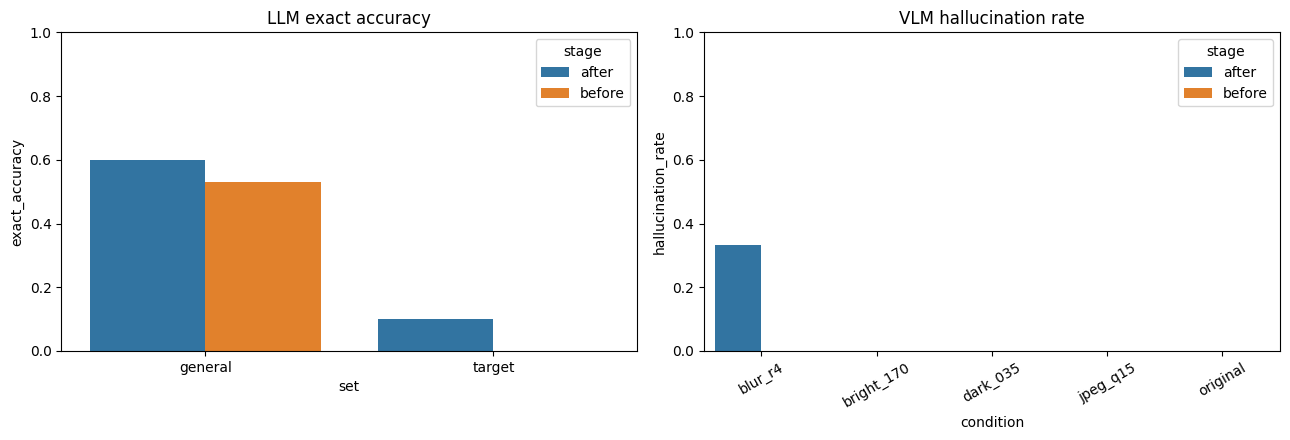

# 作業 C：DPO 微調 LLM/VLM 實驗報告

## 基礎：LLM DPO
- 模型：Qwen/Qwen2.5-0.5B-Instruct，NF4 QLoRA，DPO 120 組。
- 優化面向：正確且簡潔的繁體中文回答。
- target exact accuracy：0.0% → 10.0%（+10.0 個百分點）。
- 無關的 100 題通用 benchmark：53.0% → 60.0%（+7.0 個百分點）。

## 進階：VLM DPO
- 模型：HuggingFaceTB/SmolVLM-500M-Instruct，LoRA DPO；完整 120 組影像偏好資料以 seed=42 洗牌後分成 4 批、每批 30 組，依序更新同一 adapter。
- 優化面向：描述可見形狀時避免提及不存在物件。
- 原圖 hallucination rate：0.0% → 0.0%（+0.0 個百分點）。
- 微調後另測 original、亮度 0.35、亮度 1.70、Gaussian blur r=4、JPEG quality=15；完整數字見 `vlm_summary.csv`。

![比較圖](dpo_comparison.png)

## 結論與限制
以上結論以未進入訓練的測試集計算。LLM 通用能力以 100 題 exact match 衡量；VLM 幻覺以已知顏色—形狀詞彙集合量化。為符合 Colab T4 系統記憶體限制，VLM 採用 4×30 sequential chunk DPO：各階段沿用同一 LoRA adapter，但 Trainer、optimizer 與 scheduler 會重建，因此不完全等同於單一 120 筆標準 DPO epoch。



In [10]:
fig,ax=plt.subplots(1,2,figsize=(13,4.5))
sns.barplot(data=llm_summary,x="set",y="exact_accuracy",hue="stage",ax=ax[0]); ax[0].set_title("LLM exact accuracy"); ax[0].set_ylim(0,1)
sns.barplot(data=vlm_summary,x="condition",y="hallucination_rate",hue="stage",ax=ax[1]); ax[1].set_title("VLM hallucination rate"); ax[1].tick_params(axis="x",rotation=30); ax[1].set_ylim(0,1)
plt.tight_layout(); plt.savefig(OUT/"dpo_comparison.png",dpi=180,bbox_inches="tight"); plt.show()

def val(df,query,col): return float(df.query(query)[col].iloc[0])
before_target=val(llm_summary,"stage=='before' and set=='target'","exact_accuracy"); after_target=val(llm_summary,"stage=='after' and set=='target'","exact_accuracy")
before_general=val(llm_summary,"stage=='before' and set=='general'","exact_accuracy"); after_general=val(llm_summary,"stage=='after' and set=='general'","exact_accuracy")
vb=val(vlm_summary,"stage=='before' and condition=='original'","hallucination_rate"); va=val(vlm_summary,"stage=='after' and condition=='original'","hallucination_rate")
report=f"""# 作業 C：DPO 微調 LLM/VLM 實驗報告

## 基礎：LLM DPO
- 模型：{LLM_ID}，NF4 QLoRA，DPO 120 組。
- 優化面向：正確且簡潔的繁體中文回答。
- target exact accuracy：{before_target:.1%} → {after_target:.1%}（{(after_target-before_target)*100:+.1f} 個百分點）。
- 無關的 100 題通用 benchmark：{before_general:.1%} → {after_general:.1%}（{(after_general-before_general)*100:+.1f} 個百分點）。

## 進階：VLM DPO
- 模型：{VLM_ID}，LoRA DPO；完整 120 組影像偏好資料以 seed={SEED} 洗牌後分成 4 批、每批 30 組，依序更新同一 adapter。
- 優化面向：描述可見形狀時避免提及不存在物件。
- 原圖 hallucination rate：{vb:.1%} → {va:.1%}（{(va-vb)*100:+.1f} 個百分點）。
- 微調後另測 original、亮度 0.35、亮度 1.70、Gaussian blur r=4、JPEG quality=15；完整數字見 `vlm_summary.csv`。

![比較圖](dpo_comparison.png)

## 結論與限制
以上結論以未進入訓練的測試集計算。LLM 通用能力以 100 題 exact match 衡量；VLM 幻覺以已知顏色—形狀詞彙集合量化。為符合 Colab T4 系統記憶體限制，VLM 採用 4×30 sequential chunk DPO：各階段沿用同一 LoRA adapter，但 Trainer、optimizer 與 scheduler 會重建，因此不完全等同於單一 120 筆標準 DPO epoch。
"""
(OUT/"report_C.md").write_text(report,encoding="utf-8"); print(report)

In [11]:
assert len(llm_results)==260 and len(general)>=100 and len(llm_train)>=100 and len(vtrain)>=100
assert llm_results.groupby(["stage","set"]).size().to_dict()=={("after","general"):100,("after","target"):30,("before","general"):100,("before","target"):30}
assert len(vlm_before)==30 and len(vlm_after)==150 and len(vlm_results)==180
assert set(vlm_after.condition)=={"original","dark_035","bright_170","blur_r4","jpeg_q15"}
assert vlm_after.groupby("condition").size().eq(30).all()
assert len(vlm_chunk_logs)==4 and sum(x["examples"] for x in vlm_chunk_logs)==120
metadata={"python":platform.python_version(),"torch":torch.__version__,"transformers":transformers.__version__,"trl":trl.__version__,"gpu":torch.cuda.get_device_name(0),"seed":SEED,"llm":LLM_ID,"vlm":VLM_ID,"vlm_train_used":len(vtrain_order),"vlm_chunks":4,"vlm_chunk_size":VLM_CHUNK_SIZE}
(OUT/"environment.json").write_text(json.dumps(metadata,indent=2,ensure_ascii=False),encoding="utf-8")
print("✅ 作業 C 完整性檢查通過：LLM 260 筆、VLM 180 筆")


✅ 作業 C 完整性檢查通過：LLM 260 筆、VLM 180 筆
